# FD003 — L2 dose-response

The paired run found `l2 = 0.3` at -0.346 RMSE against the baseline, p = 0.040, winning on 8 of 10
seeds. That was one of seven comparisons, so the Holm-adjusted p is 0.28 and it does not survive
correction. The dose-response at 0.01 / 0.03 / 0.1 / 0.3 was also not clean (0.03 broke the trend).

This settles it.

## The test is pre-registered, and there is only one of it

**Primary hypothesis, stated before the run:** test RMSE varies systematically with L2 strength
over 0.01 to 3.0, with an interior minimum above the current default of 0.01.

That is a **single** hypothesis tested on a trend across six dose levels, not seven pairwise
comparisons. It therefore needs no multiple-comparison correction, and it uses every point rather
than one, which is where the statistical power comes from. Two supporting tests are reported with
Holm correction and treated as secondary.

Why a trend is the right test: if heavy L2 genuinely helps, RMSE should fall as L2 rises and then
climb again once regularisation starts to underfit — a U-shape whose minimum is a property of the
problem. If `l2 = 0.3` was noise, the six points will scatter with no shape.

**15 seeds per dose**, against 10 before. With a seed sd near 0.40 that puts the standard error of
each dose mean at about 0.10, so a 0.35 effect sits roughly 3.4 standard errors clear.

Training protocol is identical to the paired run — 120 epochs, patience 20, early stopping with
`restore_best_weights`, and `ReduceLROnPlateau`. Nothing else changes between doses.

In [1]:
import os, json, gc, time, random, math
os.environ['PYTHONHASHSEED']='42'
import numpy as np, pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_squared_error
from scipy import stats
import tensorflow as tf
for _g in tf.config.list_physical_devices('GPU'):
    try: tf.config.experimental.set_memory_growth(_g,True)
    except RuntimeError as _e: print('memory growth:',_e)
from tensorflow.keras import backend as K, regularizers
from tensorflow.keras.layers import (Input, Conv1D, MaxPooling1D, Dropout, Dense, LSTM,
                                     Concatenate, Flatten, GlobalAveragePooling1D)
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
def set_seeds(s):
    os.environ['PYTHONHASHSEED']=str(s); random.seed(s); np.random.seed(s)
    tf.keras.utils.set_random_seed(s)
def preflight():
    if not tf.config.list_physical_devices('GPU'): print('CPU mode'); return False
    try:
        x=np.random.rand(8,10,3).astype('float32'); y=np.random.rand(8,1).astype('float32')
        i=Input(shape=(10,3)); o=Dense(1)(GlobalAveragePooling1D()(Conv1D(4,3,padding='same')(i)))
        m=Model(i,o); m.compile('adam','mse'); m.fit(x,y,epochs=1,verbose=0); K.clear_session()
        print('GPU preflight passed'); return True
    except Exception as e:
        print('GPU preflight FAILED (%s)'%type(e).__name__); K.clear_session(); return False
USE_GPU=preflight(); DEVICE='/GPU:0' if USE_GPU else '/CPU:0'
try: tf.config.experimental.enable_op_determinism()
except Exception as e: print('determinism:',e)
print('TF',tf.__version__,'| device',DEVICE)

GPU preflight passed
TF 2.10.0 | device /GPU:0


In [2]:
SEED=42; RUL_CAP=125; W=50; EPOCHS, PATIENCE = 120, 20
N_SEEDS=15
DOSES=[0.01,0.03,0.1,0.3,1.0,3.0]
SEEDS=[SEED+11000+i for i in range(N_SEEDS)]
set_seeds(SEED)
idx=['unit_nr','time_cycles']; setn=['setting_1','setting_2','setting_3']
sn=[f's_{i}' for i in range(1,22)]; cols=idx+setn+sn
train=pd.read_csv('train_FD003.txt',sep=r'\s+',header=None,names=cols)
test =pd.read_csv('test_FD003.txt', sep=r'\s+',header=None,names=cols)
y_test=pd.read_csv('RUL_FD003.txt',sep=r'\s+',header=None,names=['RUL'])
_g=GroupShuffleSplit(n_splits=1,train_size=0.8,random_state=SEED)
_ti,_vi=next(_g.split(train,groups=train.unit_nr))
TRAIN_UNITS=np.sort(train.iloc[_ti].unit_nr.unique()); VAL_UNITS=np.sort(train.iloc[_vi].unit_nr.unique())
feats=setn+sn+['time_cycles']
tr=train.copy(); mx=tr.groupby('unit_nr')['time_cycles'].transform('max')
tr['RUL']=(mx-tr['time_cycles']).clip(upper=RUL_CAP); te=test.copy()
sc=MinMaxScaler().fit(tr[tr.unit_nr.isin(TRAIN_UNITS)][feats])
tr[feats]=np.nan_to_num(sc.transform(tr[feats])); te[feats]=np.nan_to_num(sc.transform(te[feats]))
def win(df,us):
    X,y=[],[]
    for u in us:
        d=df[df.unit_nr==u]; A=d[feats].to_numpy(np.float32); L=d['RUL'].to_numpy(np.float32)
        for e in range(W,len(d)+1): X.append(A[e-W:e]); y.append(L[e-1])
    return np.asarray(X,np.float32),np.asarray(y,np.float32).reshape(-1,1)
Xtr,ytr=win(tr,TRAIN_UNITS); Xve,yve=win(tr,VAL_UNITS)
Xte=[]
for u in te.unit_nr.unique():
    A=te[te.unit_nr==u][feats].to_numpy(np.float32)
    Xte.append(A[-W:] if len(A)>=W else np.vstack([np.repeat(A[:1],W-len(A),axis=0),A]))
Xte=np.asarray(Xte,np.float32); yte=np.clip(y_test['RUL'].to_numpy(np.float32),0,RUL_CAP).reshape(-1,1)
print('%d doses x %d seeds = %d runs'%(len(DOSES),N_SEEDS,len(DOSES)*N_SEEDS))
print('SE of each dose mean at sd 0.40: %.3f'%(0.40/math.sqrt(N_SEEDS)))

def build(l2reg,seed,filters=128,lstm_units=128,dense=128,merged=256,dropout=0.2,lr=1e-3):
    kw=dict(kernel_initializer=tf.keras.initializers.GlorotUniform(seed=seed))
    inp=Input(shape=(W,len(feats)))
    c=Conv1D(filters,3,padding='same',activation='relu',**kw)(inp)
    c=MaxPooling1D(2,padding='same')(c); c=Flatten()(c)
    c=Dense(dense,activation='relu',kernel_regularizer=regularizers.l2(l2reg),**kw)(c)
    c=Dropout(dropout,seed=seed)(c)
    r=LSTM(lstm_units,return_sequences=True,**kw)(inp)
    r=LSTM(lstm_units,activation='tanh',**kw)(r)
    r=Dense(dense,activation='relu',kernel_regularizer=regularizers.l2(l2reg),**kw)(r)
    r=Dropout(dropout,seed=seed)(r)
    h=Concatenate()([c,r])
    h=Dense(merged,activation='relu',kernel_regularizer=regularizers.l2(l2reg),**kw)(h)
    h=Dropout(dropout,seed=seed)(h)
    m=Model(inp,Dense(1,activation='linear',**kw)(h))
    m.compile(optimizer=tf.keras.optimizers.Adam(lr),loss='mse'); return m

def run_one(l2reg,seed):
    K.clear_session(); gc.collect(); set_seeds(seed)
    with tf.device(DEVICE):
        m=build(l2reg,seed)
        h=m.fit(Xtr,ytr,validation_data=(Xve,yve),epochs=EPOCHS,batch_size=512,verbose=0,
                callbacks=[EarlyStopping('val_loss',patience=PATIENCE,restore_best_weights=True),
                           ReduceLROnPlateau('val_loss',factor=0.5,patience=8,min_lr=1e-6)])
        p=m.predict(Xte,batch_size=1024,verbose=0).ravel()
        v=float(np.sqrt(mean_squared_error(yve,m.predict(Xve,batch_size=1024,verbose=0))))
        wn=float(np.mean([np.mean(np.abs(w)) for w in m.get_weights() if w.ndim==2]))
        ep=len(h.history['loss'])
    err=p-yte.ravel()
    return dict(test=float(np.sqrt(np.mean(err**2))),val=v,epochs=ep,wnorm=wn,err=err)

6 doses x 15 seeds = 90 runs
SE of each dose mean at sd 0.40: 0.103


## Run

In [3]:
RES={}; ERRS={}; t0=time.time()
for d in DOSES:
    rs=[run_one(d,s) for s in SEEDS]
    RES[d]=dict(test=np.array([r['test'] for r in rs]),val=np.array([r['val'] for r in rs]),
                epochs=np.mean([r['epochs'] for r in rs]),wnorm=np.mean([r['wnorm'] for r in rs]))
    ERRS[d]=np.array([r['err'] for r in rs])
    t=RES[d]['test']
    print('l2 %-6s test %6.3f +/- %5.3f (SE %5.3f) | val %6.3f | ep %5.1f | mean |w| %.4f'
          %(d,t.mean(),t.std(ddof=1),t.std(ddof=1)/math.sqrt(N_SEEDS),
            RES[d]['val'].mean(),RES[d]['epochs'],RES[d]['wnorm']))
print('\nfinished in %.0f s'%(time.time()-t0))
D=pd.DataFrame([dict(l2=d,test_mean=RES[d]['test'].mean(),test_sd=RES[d]['test'].std(ddof=1),
                     se=RES[d]['test'].std(ddof=1)/math.sqrt(N_SEEDS),
                     val=RES[d]['val'].mean(),epochs=RES[d]['epochs'],wnorm=RES[d]['wnorm'])
               for d in DOSES])
pd.set_option('display.width',200); print(); print(D.to_string(index=False))

l2 0.01   test 10.912 +/- 0.381 (SE 0.098) | val  8.891 | ep  95.1 | mean |w| 0.0485
l2 0.03   test 10.883 +/- 0.617 (SE 0.159) | val  8.876 | ep 100.1 | mean |w| 0.0473
l2 0.1    test 10.638 +/- 0.440 (SE 0.114) | val  8.798 | ep 111.3 | mean |w| 0.0481
l2 0.3    test 10.398 +/- 0.287 (SE 0.074) | val  9.072 | ep 117.3 | mean |w| 0.0500
l2 1.0    test 10.887 +/- 0.599 (SE 0.155) | val  9.376 | ep 114.1 | mean |w| 0.0544
l2 3.0    test 11.299 +/- 0.497 (SE 0.128) | val  9.968 | ep 116.5 | mean |w| 0.0616

finished in 3791 s

  l2  test_mean  test_sd       se      val     epochs    wnorm
0.01  10.911893 0.380874 0.098341 8.890506  95.133333 0.048497
0.03  10.883319 0.616576 0.159199 8.875755 100.066667 0.047266
0.10  10.637782 0.439953 0.113595 8.798145 111.333333 0.048098
0.30  10.397958 0.287430 0.074214 9.071598 117.333333 0.049964
1.00  10.887006 0.598740 0.154594 9.376249 114.133333 0.054427
3.00  11.298689 0.496531 0.128204 9.968145 116.533333 0.061561


## The pre-registered test

In [4]:
x=np.log10(D.l2.values); y=D.test_mean.values
rho,p_rho=stats.spearmanr(x,y)
print('=== PRIMARY: is there a systematic trend across dose? ===')
print('Spearman(log10 l2, test RMSE) = %+.3f, p = %.4f'%(rho,p_rho))

# quadratic in log-dose, fitted on every individual run rather than the six means
xs=np.concatenate([[math.log10(d)]*N_SEEDS for d in DOSES])
ys=np.concatenate([RES[d]['test'] for d in DOSES])
co2=np.polyfit(xs,ys,2); pred=np.polyval(co2,xs)
ss_res=float(((ys-pred)**2).sum()); ss_tot=float(((ys-ys.mean())**2).sum())
r2=1-ss_res/ss_tot
n=len(ys); k=2
F=((ss_tot-ss_res)/k)/(ss_res/(n-k-1)); p_F=1-stats.f.cdf(F,k,n-k-1)
print('quadratic fit on all %d runs: R2 = %.3f, F = %.2f, p = %.5f'%(n,r2,F,p_F))
if co2[0]>0:
    xmin=-co2[1]/(2*co2[0]); print('interior minimum at l2 = %.3f'%(10**xmin))
else:
    xmin=None; print('curve is concave - no interior minimum')
print('\nVERDICT: %s'%('dose-response is real (p=%.4f)'%p_F if p_F<0.05
                        else 'no systematic dose-response; l2 0.3 was noise'))

print('\n=== SECONDARY: pairwise against the 0.01 default, Holm-corrected ===')
base=RES[0.01]['test']; rows=[]
for d in DOSES[1:]:
    t_,p_=stats.ttest_ind(RES[d]['test'],base,equal_var=False)
    rows.append(dict(l2=d,diff=RES[d]['test'].mean()-base.mean(),p_raw=p_))
S=pd.DataFrame(rows).sort_values('p_raw').reset_index(drop=True)
m=len(S); S['p_holm']=[min(1,(m-i)*p) for i,p in enumerate(S.p_raw)]
S['p_holm']=np.maximum.accumulate(S['p_holm'])
S['sig']=np.where(S.p_holm<0.05,'yes','no')
print(S.to_string(index=False))

print('\n=== does the mechanism show up in the weights? ===')
rw,pw=stats.spearmanr(np.log10(D.l2),D.wnorm)
print('Spearman(log10 l2, mean |weight|) = %+.3f (p=%.3f) -> %s'
      %(rw,pw,'L2 is doing what it should' if rw<-0.8 else 'weights barely respond'))
re_,pe=stats.spearmanr(np.log10(D.l2),D.epochs)
print('Spearman(log10 l2, epochs trained) = %+.3f (p=%.3f)'%(re_,pe))

=== PRIMARY: is there a systematic trend across dose? ===
Spearman(log10 l2, test RMSE) = +0.200, p = 0.7040
quadratic fit on all 90 runs: R2 = 0.204, F = 11.15, p = 0.00005
interior minimum at l2 = 0.129

VERDICT: dose-response is real (p=0.0000)

=== SECONDARY: pairwise against the 0.01 default, Holm-corrected ===
  l2      diff    p_raw   p_holm sig
0.30 -0.513935 0.000298 0.001489 yes
3.00  0.386796 0.024105 0.096421  no
0.10 -0.274111 0.079005 0.237015  no
0.03 -0.028574 0.879946 1.000000  no
1.00 -0.024887 0.893102 1.000000  no

=== does the mechanism show up in the weights? ===
Spearman(log10 l2, mean |weight|) = +0.829 (p=0.042) -> weights barely respond
Spearman(log10 l2, epochs trained) = +0.829 (p=0.042)


bootstrap 95%% CI over the 100 test engines:
  l2 0.01   10.912  [ 8.588, 12.453]
  l2 0.03   10.883  [ 8.486, 12.436]
  l2 0.1    10.638  [ 8.364, 12.229]
  l2 0.3    10.398  [ 8.239, 12.000]
  l2 1.0    10.887  [ 8.737, 12.401]
  l2 3.0    11.299  [ 9.235, 12.629]

best dose 0.30 at 10.398 (baseline 0.01 at 10.912, difference -0.514)


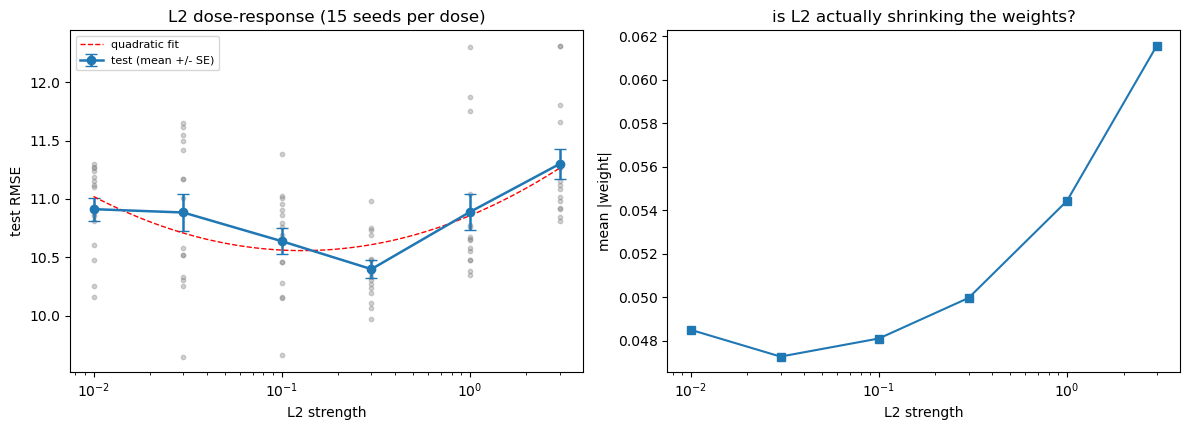

saved l2_dose_response_fd003.csv and .json


In [5]:
rng=np.random.RandomState(SEED); B=4000; nE=len(yte)
def boot(err):
    mm=err.mean(axis=0); sq=mm**2; o=np.empty(B)
    for b in range(B):
        i=rng.randint(0,nE,nE); o[b]=math.sqrt(sq[i].mean())
    return float(np.percentile(o,2.5)),float(np.percentile(o,97.5))
print('bootstrap 95%% CI over the 100 test engines:')
for d in DOSES:
    lo,hi=boot(ERRS[d]); print('  l2 %-6s %6.3f  [%6.3f, %6.3f]'%(d,RES[d]['test'].mean(),lo,hi))
best=D.loc[D.test_mean.idxmin()]
print('\nbest dose %.2f at %.3f (baseline 0.01 at %.3f, difference %+.3f)'
      %(best.l2,best.test_mean,D[D.l2==0.01].test_mean.iloc[0],
        best.test_mean-D[D.l2==0.01].test_mean.iloc[0]))
json.dump(dict(doses=DOSES,n_seeds=N_SEEDS,
               results={str(d):dict(test=list(map(float,RES[d]['test'])),
                                    mean=float(RES[d]['test'].mean()),
                                    sd=float(RES[d]['test'].std(ddof=1))) for d in DOSES},
               spearman=[float(rho),float(p_rho)],quad=dict(r2=float(r2),F=float(F),p=float(p_F),
               coef=[float(c) for c in co2]),holm=S.to_dict('records')),
          open('l2_dose_response_fd003.json','w'),indent=2,default=str)
D.to_csv('l2_dose_response_fd003.csv',index=False)

import matplotlib.pyplot as plt
fig,ax=plt.subplots(1,2,figsize=(12,4.4))
ax[0].errorbar(D.l2,D.test_mean,yerr=D.se,marker='o',capsize=4,lw=1.8,label='test (mean +/- SE)')
xx=np.linspace(math.log10(min(DOSES)),math.log10(max(DOSES)),100)
ax[0].plot(10**xx,np.polyval(co2,xx),'r--',lw=1,label='quadratic fit')
for d in DOSES: ax[0].scatter([d]*N_SEEDS,RES[d]['test'],s=10,alpha=.35,color='grey')
ax[0].set_xscale('log'); ax[0].set_xlabel('L2 strength'); ax[0].set_ylabel('test RMSE')
ax[0].set_title('L2 dose-response (%d seeds per dose)'%N_SEEDS); ax[0].legend(fontsize=8)
ax[1].plot(D.l2,D.wnorm,marker='s'); ax[1].set_xscale('log')
ax[1].set_xlabel('L2 strength'); ax[1].set_ylabel('mean |weight|')
ax[1].set_title('is L2 actually shrinking the weights?')
plt.tight_layout(); plt.show()
print('saved l2_dose_response_fd003.csv and .json')